# Vetores otimizados para a nuvem: Shapefile, GeoPackage, FlatGeobuf, GeoParquet e GeoArrow

Seminário 3 de CAP-423, por João e Matheus, em 16/11/2026.

A aula 03 comparou esses formatos em uma tabela de usos, vantagens e limitações. Este notebook testa essa tabela com dados reais, a partir de uma pergunta:

> Para responder sobre uma pequena parte de um arquivo remoto, quantos bytes precisam atravessar a rede?

Todos os formatos guardam a mesma malha, os setores censitários do Censo 2022 do IBGE. Ela é lida de um servidor que registra cada requisição, então as comparações de rede vêm de contagens.

**Resultado em resumo.** Nenhum formato vence todas as perguntas.

- **Recorte espacial** (0,44 % da malha): FlatGeobuf e GeoPackage transferem menos de 6 MB, de arquivos com cerca de 1,5 GB. O FlatGeobuf faz isso em 39 requisições, e o GeoPackage precisa de 310.
- **Consulta analítica** (2 de 30 colunas): o GeoParquet transfere cerca de 5 MB. GeoPackage e FlatGeobuf transferem o arquivo quase inteiro.
- **GeoParquet não é otimizado por definição:** o mesmo recorte custa 1,1 GB em um arquivo gravado com as opções padrão e 36 MB em um arquivo ordenado, com coluna `bbox` e grupos pequenos.
- **Shapefile:** sem o índice opcional `.qix`, o recorte transfere os 2,3 GB inteiros.
- **GeoArrow** não compete como arquivo de distribuição. O ganho dele está na memória: os dados são usados direto do arquivo, sem cópia nem decodificação.

| Seção | Conteúdo |
|---|---|
| 1 | O que torna um formato *cloud-optimized* |
| 2 | Os dados |
| 3 | Gravação nos cinco formatos |
| 4 | Por dentro de cada formato |
| 5 | O que cada formato preserva |
| 6 | Leitura local |
| 7 | Leitura remota, a medição central |
| 8 | O que faz um GeoParquet ser otimizado |
| 9 | Na rede de verdade |
| 10 | Síntese e referências |

## 0. Ambiente

O notebook roda localmente, no Python 3.13 (Miniforge). O `pyarrow` lê e grava Parquet e Arrow, e o `fsspec` com o `aiohttp` permite ao GeoPandas ler Parquet por HTTP.

Tudo o que o notebook lê fica em `input/`, e tudo o que ele gera fica em `output/`. As duas pastas estão fora do Git, porque passam do limite de 100 MB por arquivo do GitHub. Para refazer as gravações e os tempos medidos, basta apagar `output/`.

**Tempo de execução.** Neste computador, `output/` fica em um HD. A primeira execução levou cerca de 17 minutos, além do download do zip de 774 MB. As seguintes reaproveitam os arquivos e os tempos já medidos, mas refazem as medições das seções 7 e 8, que levaram cerca de 8 minutos em 01/11/2026 e mais de meia hora em 30/10/2026, com outros programas usando o mesmo disco. Para apresentar, execute o notebook antes e use as saídas salvas.

In [1]:
%pip install -q pyarrow fsspec aiohttp

Note: you may need to restart the kernel to use updated packages.


In [2]:
import atexit
import json
import socket
import sqlite3
import struct
import subprocess
import sys
import tempfile
import time
import warnings
from pathlib import Path
from time import perf_counter

import fsspec
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.ipc as ipc
import pyarrow.parquet as pq
import pyogrio
import requests
import shapely
from matplotlib.patches import Rectangle
from matplotlib.ticker import FuncFormatter
from pyarrow import fs as pafs
from shapely.geometry import Point, box

print(f"GeoPandas {gpd.__version__} | pyogrio {pyogrio.__version__} | GDAL {pyogrio.__gdal_version_string__} | pyarrow {pa.__version__}")

GeoPandas 1.2.0 | pyogrio 0.13.0 | GDAL 3.12.4 | pyarrow 26.0.0


In [3]:
INPUT_DIR = Path("input")
OUTPUT_DIR = Path("output")
INPUT_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

IBGE_SETORES = (
    "geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/"
    "malhas_de_setores_censitarios__divisoes_intramunicipais/censo_2022/setores"
)
ZIP_SETORES = INPUT_DIR / "BR_setores_CD2022.zip"

COD_SJC = "3549904"  # São José dos Campos, sede do INPE
COLUNAS = ["CD_UF", "AREA_KM2"]
RANDOM_STATE = 123
REPETICOES = 2

AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#898781"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11, "axes.titlelocation": "left",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "grid.color": "#e1e0d9",
    "font.size": 10, "savefig.facecolor": "#fcfcfb",
})


def br(valor, casas=0):
    """Número com separadores brasileiros."""
    return f"{valor:,.{casas}f}".translate(str.maketrans(",.", ".,"))


def texto_bytes(n):
    """Tamanho legível."""
    for limite, unidade in [(1e9, "GB"), (1e6, "MB"), (1e3, "KB")]:
        if n >= limite:
            return f"{br(n / limite, 1)} {unidade}"
    return f"{n:.0f} B"


def tabela(df, casas=1):
    """Tabela com separadores brasileiros."""
    return df.style.format(precision=casas, decimal=",", thousands=".", na_rep="–")

## 1. O que torna um formato *cloud-optimized*

Um arquivo em armazenamento de objetos (S3, Google Cloud Storage, Azure Blob ou um servidor HTTP comum) não é aberto como um arquivo em disco. Cada leitura é uma requisição pela rede, que pode pedir só um trecho do arquivo com o cabeçalho `Range: bytes=inicio-fim`.

A ideia é a mesma do COG, visto nas aulas 02 e 03: o arquivo continua sendo um GeoTIFF, mas a organização interna permite ler só os blocos necessários. Em um vetor, isso depende de três condições:

1. **Metadados em posição conhecida.** Esquema, CRS e a localização dos dados ficam no início ou no fim do arquivo, e poucas requisições bastam para lê-los.
2. **Um jeito de descartar dados sem lê-los.** Um índice espacial ou estatísticas por bloco indicam quais trechos podem conter a resposta.
3. **Organização física.** Feições próximas no espaço ficam próximas no arquivo, e a resposta cabe em poucos trechos contíguos.

Os cinco formatos organizam os bytes de maneiras bem diferentes:

```text
Shapefile   .shp [cabeçalho | geometria 1 | geometria 2 | ...]    .shx [posições]
            .dbf [cabeçalho | linha 1 | linha 2 | ...]            .qix [índice, opcional]
GeoPackage  [página | página | página | ...]      banco SQLite, com tabela e R-tree em páginas
FlatGeobuf  [assinatura | cabeçalho | R-tree | feição 1 | feição 2 | ...]
GeoParquet  [grupo 1: coluna A, coluna B, geometria | grupo 2: ... | rodapé com estatísticas]
GeoArrow    layout das colunas na memória; em disco, usa Arrow IPC ou Parquet
```

O custo de uma leitura remota pode ser aproximado por

$$t \approx N \cdot \text{RTT} + \frac{B}{\text{banda}}$$

em que $N$ é o número de requisições e $B$ é o total de bytes. O primeiro termo depende da latência, e o segundo, da banda. O notebook mede $N$ e $B$ separadamente, porque um formato pode ser bom em um e ruim no outro.

## 2. Os dados

A [malha de setores censitários de 2022](https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/malhas_de_setores_censitarios__divisoes_intramunicipais/censo_2022/setores/) cobre o Brasil inteiro e é publicada pelo IBGE em Shapefile compactado e em GeoPackage. O teste de leitura parcial usa o retângulo envolvente de São José dos Campos, que seleciona uma fração muito pequena da malha e inclui setores de municípios vizinhos.

In [4]:
PARQUET_PADRAO = OUTPUT_DIR / "setores_padrao.parquet"

if PARQUET_PADRAO.exists():
    # Depois da primeira execução, o GeoParquet evita reler o zip, que leva minutos.
    setores = gpd.read_parquet(PARQUET_PADRAO)
else:
    if not ZIP_SETORES.exists():
        parcial = ZIP_SETORES.with_suffix(".parcial")
        with requests.get(f"https://{IBGE_SETORES}/shp/BR/BR_setores_CD2022.zip", stream=True, timeout=120) as resposta:
            resposta.raise_for_status()
            with open(parcial, "wb") as destino:
                for bloco in resposta.iter_content(1024 * 1024):
                    destino.write(bloco)
        parcial.rename(ZIP_SETORES)
    setores = gpd.read_file(ZIP_SETORES, use_arrow=True)

BBOX = tuple(float(v) for v in setores.loc[setores["CD_MUN"] == COD_SJC].total_bounds)
recorte = setores[setores.intersects(box(*BBOX))]
N_RECORTE = len(recorte)
n_vertices = int(shapely.get_num_coordinates(setores.geometry.values).sum())

print(f"Setores: {br(len(setores))}")
print(f"Vértices: {br(n_vertices)}, média de {br(n_vertices / len(setores))} por setor")
print(f"Colunas de atributos: {setores.shape[1] - 1}")
print("CRS:", setores.crs.to_string())
print("Geometrias:", setores.geom_type.value_counts().to_dict())
print(f"Retângulo de São José dos Campos: {br(N_RECORTE)} setores ({br(100 * N_RECORTE / len(setores), 2)} % da malha)")

Setores: 468.099
Vértices: 76.519.789, média de 163 por setor
Colunas de atributos: 29
CRS: EPSG:4674
Geometrias: {'Polygon': 467185, 'MultiPolygon': 914}
Retângulo de São José dos Campos: 2.054 setores (0,44 % da malha)


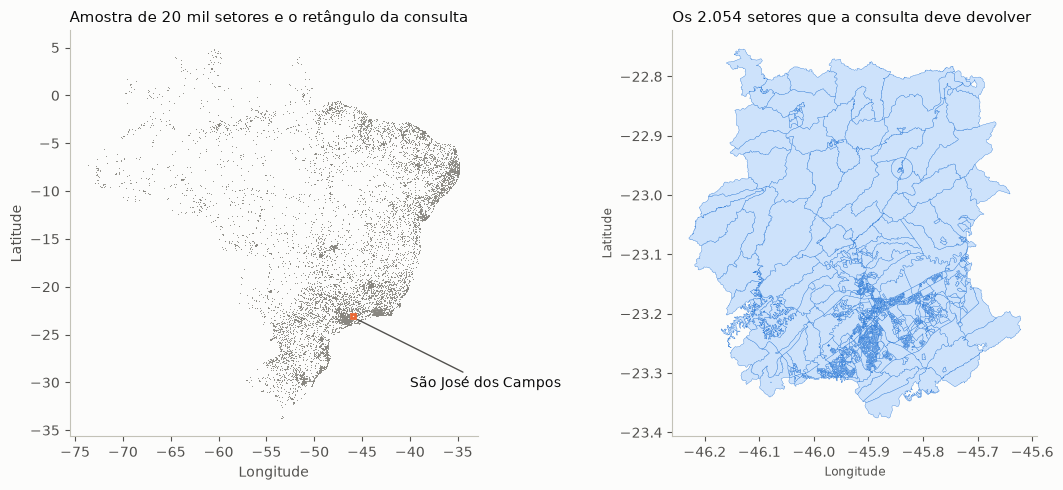

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))

amostra = setores.sample(20_000, random_state=RANDOM_STATE).geometry.representative_point()
ax1.scatter(amostra.x, amostra.y, s=0.4, color=CINZA, linewidths=0)
ax1.add_patch(Rectangle(BBOX[:2], BBOX[2] - BBOX[0], BBOX[3] - BBOX[1], fill=False, edgecolor=LARANJA, linewidth=2))
ax1.annotate("São José dos Campos", xy=(BBOX[2], BBOX[1]), xytext=(-40, -30.5), color="#0b0b0b",
             arrowprops=dict(arrowstyle="-", color="#52514e"))
ax1.set(title="Amostra de 20 mil setores e o retângulo da consulta", xlabel="Longitude", ylabel="Latitude")
ax1.set_aspect("equal")

recorte.plot(ax=ax2, facecolor="#cde2fb", edgecolor=AZUL, linewidth=0.25)
ax2.set(title=f"Os {br(N_RECORTE)} setores que a consulta deve devolver", xlabel="Longitude", ylabel="Latitude")
plt.tight_layout()
plt.show()

## 3. Gravação nos cinco formatos

Cada formato é gravado da forma mais próxima do que se faz na prática:

| Arquivo | Como é gravado |
|---|---|
| Shapefile | Com `.qix`, o índice espacial opcional. A seção 7 também testa sem ele |
| GeoPackage | Opções padrão do GDAL, que já criam a R-tree |
| FlatGeobuf | Opções padrão do GDAL, que já criam o índice e ordenam as feições pela curva de Hilbert |
| GeoParquet padrão | `to_parquet()` sem opções |
| GeoParquet otimizado | Feições em ordem de Hilbert, coluna `bbox`, compressão zstd e grupos de 10 mil linhas |
| GeoArrow (IPC) | Geometria no layout nativo do GeoArrow, em arquivo Arrow sem compressão |

Os parâmetros do GeoParquet otimizado são discutidos na seção 8. Os tempos ficam guardados em `output/tempos.json`, e um arquivo que já existe não é gravado de novo.

In [6]:
arquivo_tempos = OUTPUT_DIR / "tempos.json"
tempos = json.loads(arquivo_tempos.read_text()) if arquivo_tempos.exists() else {}


def gravar(nome, caminho, funcao):
    """Grava uma vez e guarda o tempo medido."""
    if nome not in tempos or not caminho.exists():
        inicio = perf_counter()
        funcao(caminho)
        tempos[nome] = perf_counter() - inicio
        arquivo_tempos.write_text(json.dumps(tempos, indent=2))
    return caminho


def tamanho(caminho):
    """Soma as partes de um arquivo. Só o Shapefile tem mais de uma."""
    return sum(parte.stat().st_size for parte in caminho.parent.glob(caminho.stem + ".*"))


def gravar_geoarrow(gdf, caminho):
    tabela_arrow = pa.table(gdf.to_arrow(geometry_encoding="geoarrow"))
    with ipc.new_file(caminho, tabela_arrow.schema) as escritor:
        escritor.write_table(tabela_arrow, max_chunksize=50_000)


ordem_hilbert = np.argsort(setores.geometry.hilbert_distance().to_numpy(), kind="stable")
setores_hilbert = setores.iloc[ordem_hilbert].reset_index(drop=True)
OTIMIZADO = dict(
    compression="zstd", compression_level=9, write_covering_bbox=True,
    schema_version="1.1.0", row_group_size=10_000,
)

ARQUIVOS = {
    "Shapefile": gravar("Shapefile", OUTPUT_DIR / "setores_shape.shp",
                        lambda p: setores.to_file(p, SPATIAL_INDEX="YES", encoding="UTF-8")),
    "GeoPackage": gravar("GeoPackage", OUTPUT_DIR / "setores_gpkg.gpkg",
                         lambda p: setores.to_file(p, driver="GPKG", layer="setores")),
    "FlatGeobuf": gravar("FlatGeobuf", OUTPUT_DIR / "setores_fgb.fgb",
                         lambda p: setores.to_file(p, driver="FlatGeobuf")),
    "GeoParquet padrão": gravar("GeoParquet padrão", PARQUET_PADRAO,
                                lambda p: setores.to_parquet(p)),
    "GeoParquet otimizado": gravar("GeoParquet otimizado", OUTPUT_DIR / "setores_otimizado.parquet",
                                   lambda p: setores_hilbert.to_parquet(p, **OTIMIZADO)),
    "GeoArrow (IPC)": gravar("GeoArrow (IPC)", OUTPUT_DIR / "setores_geoarrow.arrow",
                             lambda p: gravar_geoarrow(setores, p)),
}

gravacao = pd.DataFrame({
    "Tamanho (MB)": {nome: tamanho(c) / 1e6 for nome, c in ARQUIVOS.items()},
    "Gravação (s)": {nome: tempos[nome] for nome in ARQUIVOS},
})
tabela(gravacao)

,Tamanho (MB),Gravação (s)
Shapefile,"2.343,5","56,1"
GeoPackage,"1.493,0","30,4"
FlatGeobuf,"1.426,9","46,5"
GeoParquet padrão,"1.055,7","10,5"
GeoParquet otimizado,"589,7","29,5"
GeoArrow (IPC),"1.410,6","15,0"


O Shapefile é o maior, com 2,3 GB, porque o `.dbf` reserva o mesmo espaço para cada linha (seção 4.1). O GeoParquet otimizado fica com 590 MB, um quarto disso e 44 % menos que o GeoParquet padrão. A seção 8 mostra de onde vem essa diferença.

Os tempos de gravação só servem para comparar os formatos nesta máquina, porque dependem muito do disco. A pasta `output/` está em um HD, e o mesmo Shapefile levou 22 s em um teste no SSD.

## 4. Por dentro de cada formato

Antes de medir, vale abrir os arquivos e olhar os bytes. Cada subseção mostra onde estão os três elementos da seção 1: metadados, mecanismo de descarte e organização física.

### 4.1 Shapefile

A especificação publicada pela Esri é de 1998, e o formato guarda cada aspecto dos dados em um arquivo separado. A [documentação do GDAL](https://gdal.org/en/stable/drivers/vector/shapefile.html) registra as limitações: nomes de coluna com até 10 caracteres, poucos tipos de atributo, sem data com hora, e a recomendação de não passar de 2 GB em `.shp` e `.dbf`.

In [7]:
shp = ARQUIVOS["Shapefile"]
for parte in sorted(shp.parent.glob(shp.stem + ".*")):
    print(f"{parte.suffix:5s} {texto_bytes(parte.stat().st_size):>10s}")

with open(shp, "rb") as f:
    cabecalho = f.read(100)
codigo = struct.unpack(">i", cabecalho[:4])[0]
versao, tipo = struct.unpack("<ii", cabecalho[28:36])
print(f"\n.shp: código {codigo}, versão {versao}, tipo de forma {tipo} (5 = polígono)")
print("Extensão no cabeçalho:", " | ".join(br(v, 2) for v in struct.unpack("<4d", cabecalho[36:68])))

with open(shp.with_suffix(".dbf"), "rb") as f:
    n_linhas, _, bytes_por_linha = struct.unpack("<IHH", f.read(12)[4:12])
print(f"\n.dbf: {br(n_linhas)} linhas de {br(bytes_por_linha)} bytes cada, sem compressão")

.cpg         5 B
.dbf      1,1 GB
.prj       151 B
.qix      5,5 MB
.shp      1,3 GB
.shx      3,7 MB

.shp: código 9994, versão 1000, tipo de forma 5 (5 = polígono)
Extensão no cabeçalho: -73,99 | -33,75 | -28,85 | 5,27

.dbf: 468.099 linhas de 2.315 bytes cada, sem compressão


Cada linha do `.dbf` ocupa 2.315 bytes, mesmo com os campos vazios, o que dá 1,1 GB só de atributos. O `.shp` e o `.dbf` ainda estão abaixo dos 2 GB recomendados, mas a malha nacional já ocupa mais da metade desse limite em cada um.

O `.qix` é opcional e usa o mesmo formato do MapServer, e a Esri tem outros arquivos de índice (`.sbn` e `.sbx`). Quem recebe um Shapefile não pode contar com ele, e a seção 7 mostra o que isso custa.

### 4.2 GeoPackage

O [GeoPackage](https://www.geopackage.org/) é um padrão OGC, hoje na versão 1.4, e cada arquivo é um banco SQLite. Por isso dá para abri-lo com o `sqlite3` da biblioteca padrão do Python e consultar o índice com SQL comum.

In [8]:
gpkg = sqlite3.connect(f"file:{ARQUIVOS['GeoPackage'].as_posix()}?immutable=1", uri=True)
pagina = gpkg.execute("PRAGMA page_size").fetchone()[0]
n_paginas = gpkg.execute("PRAGMA page_count").fetchone()[0]
print(f"Páginas: {br(n_paginas)} de {br(pagina)} bytes")
print("Tabelas:", [t for (t,) in gpkg.execute("SELECT name FROM sqlite_master WHERE type = 'table' ORDER BY name")])
print("Geometria:", gpkg.execute("SELECT table_name, column_name, geometry_type_name, srs_id FROM gpkg_geometry_columns").fetchone())

n_rtree = gpkg.execute(
    "SELECT count(*) FROM rtree_setores_geom WHERE maxx >= ? AND minx <= ? AND maxy >= ? AND miny <= ?",
    (BBOX[0], BBOX[2], BBOX[1], BBOX[3]),
).fetchone()[0]
print(f"Caixas da R-tree que cruzam o retângulo: {br(n_rtree)}")
gpkg.close()

Páginas: 364.502 de 4.096 bytes
Tabelas: ['gpkg_contents', 'gpkg_extensions', 'gpkg_geometry_columns', 'gpkg_ogr_contents', 'gpkg_spatial_ref_sys', 'gpkg_tile_matrix', 'gpkg_tile_matrix_set', 'rtree_setores_geom', 'rtree_setores_geom_node', 'rtree_setores_geom_parent', 'rtree_setores_geom_rowid', 'setores', 'sqlite_sequence']
Geometria: ('setores', 'geom', 'MULTIPOLYGON', 4674)
Caixas da R-tree que cruzam o retângulo: 2.055


O arquivo é uma sequência de 364.502 páginas de 4 KB, e as tabelas e a R-tree são árvores espalhadas por essas páginas. Esse desenho é ótimo para disco, com um único arquivo, várias camadas e SQL. Em rede, cada nível de árvore percorrido pode virar mais uma requisição.

A R-tree devolve 2.055 caixas, uma a mais que os 2.054 setores que cruzam o retângulo, porque compara retângulos envolventes, não os polígonos.

### 4.3 FlatGeobuf

O [FlatGeobuf](https://flatgeobuf.org/) foi desenhado para esse tipo de acesso. O arquivo tem uma assinatura de 8 bytes, um cabeçalho em FlatBuffer, uma R-tree de Hilbert compactada e as feições na mesma ordem do índice. O formato não tem compressão, para preservar o acesso aleatório, nem escrita aleatória, para manter os dados agrupados na R-tree.

O código abaixo não decodifica o cabeçalho. Ele assume nós de 16 filhos, o padrão do formato, calcula o tamanho do índice e confere a conta percorrendo as feições até o fim do arquivo.

In [9]:
fgb = ARQUIVOS["FlatGeobuf"]
# O buffer grande faz os saltos abaixo virarem uma leitura sequencial, o que importa em HD.
with open(fgb, "rb", buffering=16 * 1024 * 1024) as f:
    assinatura = f.read(8)
    tam_cabecalho = struct.unpack("<I", f.read(4))[0]

    niveis = [len(setores)]
    while niveis[-1] > 1:
        niveis.append((niveis[-1] + 15) // 16)
    tam_indice = sum(niveis) * 40  # cada nó guarda 4 doubles e um deslocamento

    posicao = 12 + tam_cabecalho + tam_indice
    fim, n_feicoes = fgb.stat().st_size, 0
    while posicao < fim:
        f.seek(posicao)
        posicao += 4 + struct.unpack("<I", f.read(4))[0]
        n_feicoes += 1

print(f"Assinatura: {assinatura.hex()} (versão {assinatura[3]} do formato)")
print(f"Cabeçalho: {texto_bytes(tam_cabecalho)}")
print(f"Índice: {niveis} nós por nível, {texto_bytes(tam_indice)}")
print(f"Feições percorridas: {br(n_feicoes)}. A última termina no fim do arquivo: {posicao == fim}")

Assinatura: 6667620366676201 (versão 3 do formato)
Cabeçalho: 1,9 KB
Índice: [468099, 29257, 1829, 115, 8, 1] nós por nível, 20,0 MB
Feições percorridas: 468.099. A última termina no fim do arquivo: True


A conta fecha: as feições terminam exatamente no fim do arquivo. O índice ocupa 20 MB, 1,4 % do total, e fica logo depois do cabeçalho, com as feições na mesma ordem de Hilbert. Por isso uma consulta pequena cai em poucos trechos contíguos. O preço é que, sem compressão e gravado em linhas, o arquivo continua com 1,4 GB, e ler uma coluna exige passar por todas as geometrias.

### 4.4 GeoParquet

O [GeoParquet](https://geoparquet.org/) é uma convenção sobre o Parquet: colunas agrupadas em *row groups*, com um rodapé que guarda o esquema, a posição de cada coluna e estatísticas de mínimo e máximo. O formato não tem índice espacial. O descarte vem das estatísticas da coluna `bbox`, e por isso a ordem das linhas importa tanto.

A versão estável é a [1.1.0](https://github.com/opengeospatial/geoparquet/releases), que introduziu a coluna `bbox` e as codificações nativas do GeoArrow. A 2.0 estava em *release candidate* em 01/11/2026 e troca as duas coisas pelos tipos `GEOMETRY` e `GEOGRAPHY` do próprio Parquet. O site do projeto descreve o GeoParquet como um padrão em incubação na OGC.

In [10]:
meta = pq.read_metadata(ARQUIVOS["GeoParquet otimizado"])
geo = json.loads(meta.metadata[b"geo"])
coluna_geo = geo["columns"]["geometry"]
print(f"GeoParquet {geo['version']} | codificação {coluna_geo['encoding']} | tipos {coluna_geo['geometry_types']}")
print("Coluna de caixas:", coluna_geo["covering"]["bbox"]["xmin"][0])
print(f"{meta.num_row_groups} grupos, {meta.num_columns} colunas físicas, rodapé de {texto_bytes(meta.serialized_size)}")

por_coluna = {}
for i in range(meta.num_row_groups):
    grupo = meta.row_group(i)
    for j in range(grupo.num_columns):
        coluna = grupo.column(j)
        por_coluna[coluna.path_in_schema] = por_coluna.get(coluna.path_in_schema, 0) + coluna.total_compressed_size
por_coluna = pd.Series(por_coluna).sort_values(ascending=False)

grupo = meta.row_group(0)
nomes = {grupo.column(j).path_in_schema: j for j in range(grupo.num_columns)}
xmin, ymax = grupo.column(nomes["bbox.xmin"]).statistics, grupo.column(nomes["bbox.ymax"]).statistics
print(f"Estatísticas do grupo 0: xmin a partir de {br(xmin.min, 2)}, ymax até {br(ymax.max, 2)}")

bytes_atributos = por_coluna.drop(["geometry", "bbox.xmin", "bbox.ymin", "bbox.xmax", "bbox.ymax"]).sum()
print(f"Geometria: {texto_bytes(por_coluna['geometry'])} ({br(100 * por_coluna['geometry'] / por_coluna.sum())} % do arquivo)")
print(f"Coluna bbox: {texto_bytes(por_coluna.filter(like='bbox').sum())}")
print(f"Atributos: {texto_bytes(bytes_atributos)}, contra {texto_bytes(n_linhas * bytes_por_linha)} no .dbf")

GeoParquet 1.1.0 | codificação WKB | tipos ['MultiPolygon', 'Polygon']
Coluna de caixas: bbox
47 grupos, 34 colunas físicas, rodapé de 212,7 KB
Estatísticas do grupo 0: xmin a partir de -57,65, ymax até -27,40
Geometria: 565,8 MB (96 % do arquivo)
Coluna bbox: 15,2 MB
Atributos: 8,4 MB, contra 1,1 GB no .dbf


A geometria responde por 96 % do arquivo. Os 29 atributos ocupam 8,4 MB, contra 1,1 GB no `.dbf`, porque colunas com valores repetidos comprimem muito bem. Essa divisão explica dois resultados das próximas seções: em um recorte, pedir menos atributos quase não economiza nada, e em uma consulta analítica, dispensar a geometria economiza quase tudo.

### 4.5 GeoArrow

O [GeoArrow](https://github.com/geoarrow/geoarrow/blob/main/format.md) é diferente dos outros quatro: é uma especificação de como guardar geometrias em colunas Arrow na memória, não um formato de arquivo. Ele define dois caminhos:

- **Serializado:** a geometria continua em WKB ou WKT, um valor binário por feição.
- **Nativo:** as coordenadas ficam em blocos contínuos de números, e listas de deslocamentos indicam onde começa cada parte. Um `MultiPolygon` vira `List<List<List<Coordinate>>>`.

Em disco, a mesma estrutura pode ir para um arquivo Arrow IPC, usado aqui, ou para dentro de um Parquet. A vantagem aparece ao ler o arquivo Arrow com mapeamento de memória: nada é copiado nem decodificado.

In [11]:
amostra_wkb = pa.table(setores.iloc[:1].to_arrow(geometry_encoding="WKB")).schema.field("geometry")
print("Serializado:", amostra_wkb.type, "|", amostra_wkb.metadata[b"ARROW:extension:name"].decode())

alocado_antes = pa.total_allocated_bytes()
inicio = perf_counter()
mapa = pa.memory_map(str(ARQUIVOS["GeoArrow (IPC)"]), "r")
tabela_mapeada = ipc.open_file(mapa).read_all()
t_mapa = perf_counter() - inicio
campo = tabela_mapeada.schema.field("geometry")
print("Nativo:     ", campo.type, "|", campo.metadata[b"ARROW:extension:name"].decode())
print(f"\nAbrir {texto_bytes(ARQUIVOS['GeoArrow (IPC)'].stat().st_size)} com mapeamento de memória: {br(t_mapa, 2)} s, "
      f"{texto_bytes(pa.total_allocated_bytes() - alocado_antes)} alocados")

lote = tabela_mapeada["geometry"].chunk(0)
poligonos = lote.values
aneis = poligonos.values
vertices = aneis.values
coordenadas = vertices.values.to_numpy(zero_copy_only=True)
print(f"\nPrimeiro lote: {br(len(lote))} feições, {br(len(poligonos))} polígonos, {br(len(aneis))} anéis e {br(len(vertices))} vértices")
print("Vértices do primeiro anel: do", aneis.offsets[0].as_py(), "ao", aneis.offsets[1].as_py())
print("Primeiras coordenadas (x, y, x, y):", " | ".join(br(v, 4) for v in coordenadas[:4]))
print("O NumPy só aponta para o bloco do arquivo:", not coordenadas.flags.owndata)

Serializado: binary | geoarrow.wkb
Nativo:      list<polygons: list<rings: list<vertices: fixed_size_list<xy: double not null>[2] not null> not null> not null> | geoarrow.multipolygon

Abrir 1,4 GB com mapeamento de memória: 0,09 s, 0 B alocados

Primeiro lote: 50.000 feições, 53.219 polígonos, 62.932 anéis e 16.603.677 vértices
Vértices do primeiro anel: do 0 ao 11
Primeiras coordenadas (x, y, x, y): -67,8381 | -9,9346 | -67,8386 | -9,9357
O NumPy só aponta para o bloco do arquivo: True


In [12]:
inicio = perf_counter()
soma_area = pc.sum(tabela_mapeada["AREA_KM2"]).as_py()
t_soma = perf_counter() - inicio

inicio = perf_counter()
xmin_nativo = min(
    lote.values.values.values.values.to_numpy(zero_copy_only=True)[::2].min()
    for lote in tabela_mapeada["geometry"].chunks
)
t_xmin = perf_counter() - inicio

inicio = perf_counter()
convertido = gpd.GeoDataFrame.from_arrow(tabela_mapeada)
t_conversao = perf_counter() - inicio

print(f"Somar AREA_KM2 direto no arquivo mapeado: {br(t_soma * 1000)} ms ({br(soma_area)} km²)")
print(f"Achar o x mínimo em {br(n_vertices / 1e6, 1)} milhões de vértices: {br(t_xmin * 1000)} ms ({br(xmin_nativo, 2)})")
print(f"Converter para GeoDataFrame, criando os objetos do Shapely: {br(t_conversao, 2)} s")
print("Tipos depois da conversão:", convertido.geom_type.value_counts().to_dict())
del convertido

Somar AREA_KM2 direto no arquivo mapeado: 1 ms (8.510.417 km²)
Achar o x mínimo em 76,5 milhões de vértices: 303 ms (-73,99)
Converter para GeoDataFrame, criando os objetos do Shapely: 0,98 s
Tipos depois da conversão: {'MultiPolygon': 468099}


O Arrow abre o arquivo sem alocar memória e sem decodificar nada: as colunas apontam para o arquivo mapeado, e somar uma coluna ou percorrer as 76,5 milhões de coordenadas leva menos de meio segundo.

Os bytes ainda precisam sair do disco. Em um teste à parte, em 01/11/2026, com o arquivo fora do cache do Windows, ler todos os lotes fez o sistema carregar o arquivo inteiro, e ler só um lote carregou apenas o trecho dele. Por isso o tempo de abertura depende do cache: de 8 a 10 s neste HD com o arquivo fora dele, e menos de meio segundo com o arquivo já em cache.

O ganho dura enquanto os dados ficam em Arrow. A conversão para objetos do Shapely leva de 1 a 2 s. Além disso, a codificação nativa exige um único tipo por coluna, então os 467.185 `Polygon` voltaram como `MultiPolygon`.

O GeoArrow também aparece onde não se vê: o `use_arrow=True` da seção 6 e a coluna `geoarrow.wkb` dos arquivos GeoParquet usam a mesma especificação.

## 5. O que cada formato preserva

Uma comparação de desempenho só vale se os dados voltam iguais. Aqui, uma tabela pequena vai e volta por cada formato, uma característica de cada vez. Os valores são comparados depois de ordenar pela coluna `id`, exceto no teste da própria ordem das linhas.

O resultado descreve o que acontece com GeoPandas e GDAL nas versões instaladas, e não tudo o que a especificação de cada formato permite.

In [13]:
pontos = gpd.GeoDataFrame(
    {"id": [1, 2, 3]},
    geometry=[Point(-45.88, -23.18), Point(-46.63, -23.55), Point(-43.2, -22.9)],
    crs=4326,
)
datas = pd.to_datetime(["2026-11-16 14:30", "2026-11-16 15:00", "2026-11-16 15:30"])
mista = gpd.GeoDataFrame({"id": [1, 2]}, geometry=[Point(0, 0), box(0, 0, 1, 1)], crs=4326)
poli_multi = gpd.GeoDataFrame({"id": [1, 2]}, geometry=[box(0, 0, 1, 1), box(0, 0, 1, 1).union(box(2, 2, 3, 3))], crs=4326)

CASOS = {
    "Nome de coluna com mais de 10 caracteres": (
        pontos.assign(nome_de_coluna_longo=[1, 2, 3]),
        lambda g, o: "nome_de_coluna_longo" in g.columns),
    "Acentos": (
        pontos.assign(nome=["São José", "Paraná", "Goiás"]),
        lambda g, o: list(g["nome"]) == list(o["nome"])),
    "Data com hora": (
        pontos.assign(quando=datas),
        lambda g, o: pd.api.types.is_datetime64_any_dtype(g["quando"]) and list(g["quando"]) == list(o["quando"])),
    "Booleano": (
        pontos.assign(ativo=[True, False, True]),
        lambda g, o: g["ativo"].dtype == bool and list(g["ativo"]) == list(o["ativo"])),
    "Inteiro nulo": (
        pontos.assign(contagem=pd.array([10, None, 30], dtype="Int64")),
        lambda g, o: list(g["contagem"].isna()) == list(o["contagem"].isna()) and g["contagem"].dropna().tolist() == o["contagem"].dropna().tolist()),
    "Lista em uma célula": (
        pontos.assign(tags=[["a", "b"], ["c"], ["d"]]),
        lambda g, o: [list(v) for v in g["tags"]] == [list(v) for v in o["tags"]]),
    "Ponto e polígono na mesma camada": (
        mista, lambda g, o: list(g.geom_type) == list(o.geom_type)),
    "Polygon e MultiPolygon na mesma camada": (
        poli_multi, lambda g, o: list(g.geom_type) == list(o.geom_type)),
    "CRS": (
        pontos.to_crs(5880), lambda g, o: g.crs == o.crs),
}


def ida_e_volta(gdf, formato, pasta):
    caminho = Path(pasta) / f"teste.{formato}"
    if formato in ("shp", "gpkg", "fgb"):
        gdf.to_file(caminho)
        return gpd.read_file(caminho)
    if formato == "parquet":
        gdf.to_parquet(caminho)
        return gpd.read_parquet(caminho)
    gravar_geoarrow(gdf, caminho)
    with pa.OSFile(str(caminho), "rb") as origem:
        return gpd.GeoDataFrame.from_arrow(ipc.open_file(origem).read_all())


FORMATOS = {"Shapefile": "shp", "GeoPackage": "gpkg", "FlatGeobuf": "fgb", "GeoParquet": "parquet", "GeoArrow": "arrow"}
fidelidade = {nome: {} for nome in FORMATOS}
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for caso, (gdf, confere) in CASOS.items():
        for nome, formato in FORMATOS.items():
            with tempfile.TemporaryDirectory(ignore_cleanup_errors=True) as pasta:
                try:
                    volta = ida_e_volta(gdf, formato, pasta).sort_values("id").reset_index(drop=True)
                    ok = confere(volta, gdf.sort_values("id").reset_index(drop=True))
                    fidelidade[nome][caso] = "preserva" if ok else "altera"
                except Exception:
                    fidelidade[nome][caso] = "não grava"

    for nome, formato in FORMATOS.items():
        with tempfile.TemporaryDirectory(ignore_cleanup_errors=True) as pasta:
            mesma_ordem = list(ida_e_volta(pontos, formato, pasta)["id"]) == list(pontos["id"])
            fidelidade[nome]["Ordem das linhas"] = "preserva" if mesma_ordem else "altera"

pd.DataFrame(fidelidade)

,Shapefile,GeoPackage,FlatGeobuf,GeoParquet,GeoArrow
Nome de coluna com mais de 10 caracteres,altera,preserva,preserva,preserva,preserva
Acentos,preserva,preserva,preserva,preserva,preserva
Data com hora,altera,preserva,preserva,preserva,preserva
Booleano,preserva,preserva,preserva,preserva,preserva
Inteiro nulo,preserva,preserva,preserva,preserva,preserva
Lista em uma célula,altera,altera,altera,preserva,preserva
Ponto e polígono na mesma camada,não grava,preserva,preserva,preserva,não grava
Polygon e MultiPolygon na mesma camada,preserva,altera,altera,preserva,altera
CRS,preserva,preserva,preserva,preserva,preserva
Ordem das linhas,preserva,preserva,altera,preserva,preserva


- **GeoParquet** foi o único que preservou tudo.
- **Shapefile** é o que mais altera: corta o nome da coluna em 10 caracteres, transforma data com hora em texto e não aceita ponto e polígono na mesma camada.
- **Listas** só sobrevivem em GeoParquet e GeoArrow. Nos outros três formatos, viram texto, como `"['a', 'b']"`.
- **FlatGeobuf** reordena as linhas pela curva de Hilbert, porque é isso que torna o índice eficiente. Código que depende da posição da linha precisa de uma coluna de identificação.
- **`Polygon` e `MultiPolygon` juntos:** GeoPackage, FlatGeobuf e GeoArrow gravam tudo como `MultiPolygon`. Nos dois primeiros, é o comportamento padrão do `pyogrio`, e `to_file(..., promote_to_multi=False)` preserva os tipos originais.
- **GeoArrow com ponto e polígono:** a falha é da codificação nativa no GeoPandas. A especificação também define um tipo de união e o WKB, que aceitam a mistura.

A malha real também voltou igual. Em um teste à parte, em 01/11/2026, as 468.099 linhas dos seis arquivos da seção 3 foram comparadas com o zip do IBGE. Os códigos e os atributos são idênticos, e as geometrias também, depois de normalizadas, o que desconsidera a ordem dos vértices e a diferença entre `Polygon` e `MultiPolygon`.

## 6. Leitura local

Em disco, o que importa é a velocidade de decodificação. A tabela mostra o menor tempo de duas leituras do arquivo inteiro, guardado em `output/tempos.json`. Nos formatos lidos pelo GDAL, a segunda coluna usa `use_arrow=True`: o GDAL entrega os dados em colunas Arrow, em vez de passá-los feição por feição ao Python. Nesse caminho a geometria vem como WKB, em uma coluna marcada como GeoArrow.

In [14]:
def menor_tempo(nome, funcao):
    """Mede uma vez e guarda o menor tempo, porque a leitura fora do cache pode levar minutos."""
    if nome not in tempos:
        medidas = []
        for _ in range(REPETICOES):
            inicio = perf_counter()
            funcao()
            medidas.append(perf_counter() - inicio)
        tempos[nome] = min(medidas)
        arquivo_tempos.write_text(json.dumps(tempos, indent=2))
    return tempos[nome]


def ler_geoarrow_local():
    origem = pa.memory_map(str(ARQUIVOS["GeoArrow (IPC)"]), "r")
    return gpd.GeoDataFrame.from_arrow(ipc.open_file(origem).read_all())


leitura_local = pd.DataFrame(index=ARQUIVOS, columns=["Leitura (s)", "Com use_arrow (s)"], dtype=float)
for nome in ["Shapefile", "GeoPackage", "FlatGeobuf"]:
    leitura_local.loc[nome, "Leitura (s)"] = menor_tempo(f"Leitura de {nome}", lambda: gpd.read_file(ARQUIVOS[nome]))
    leitura_local.loc[nome, "Com use_arrow (s)"] = menor_tempo(f"Leitura de {nome} com Arrow", lambda: gpd.read_file(ARQUIVOS[nome], use_arrow=True))
for nome in ["GeoParquet padrão", "GeoParquet otimizado"]:
    leitura_local.loc[nome, "Leitura (s)"] = menor_tempo(f"Leitura de {nome}", lambda: gpd.read_parquet(ARQUIVOS[nome]))
leitura_local.loc["GeoArrow (IPC)", "Leitura (s)"] = menor_tempo("Leitura de GeoArrow (IPC)", ler_geoarrow_local)

_, arrow_gdal = pyogrio.read_arrow(ARQUIVOS["FlatGeobuf"], max_features=1)
campo_gdal = arrow_gdal.schema.field(arrow_gdal.schema.names[-1])
print("Geometria entregue pelo GDAL:", campo_gdal.name, "|", campo_gdal.type, "|", campo_gdal.metadata[b"ARROW:extension:name"].decode())
tabela(leitura_local)

Geometria entregue pelo GDAL: wkb_geometry | binary | geoarrow.wkb


,Leitura (s),Com use_arrow (s)
Shapefile,"11,1","8,5"
GeoPackage,"11,1","4,8"
FlatGeobuf,"10,8","6,1"
GeoParquet padrão,"4,8",–
GeoParquet otimizado,"3,9",–
GeoArrow (IPC),"2,1",–


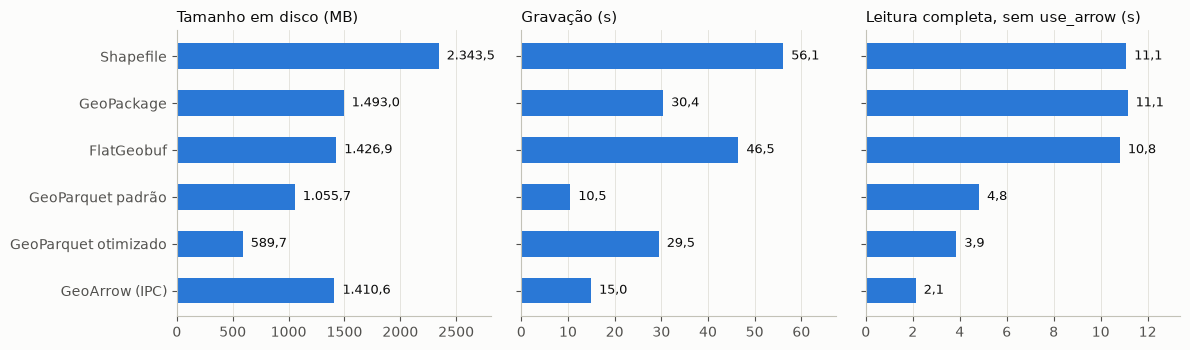

In [15]:
fig, eixos = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
paineis = [
    (gravacao["Tamanho (MB)"], "Tamanho em disco (MB)"),
    (gravacao["Gravação (s)"], "Gravação (s)"),
    (leitura_local["Leitura (s)"], "Leitura completa, sem use_arrow (s)"),
]
for ax, (serie, titulo) in zip(eixos, paineis):
    y = np.arange(len(serie))[::-1]
    ax.barh(y, serie.to_numpy(), color=AZUL, height=0.55)
    ax.set_yticks(y, serie.index)
    ax.set_title(titulo)
    ax.grid(axis="x", linewidth=0.6)
    ax.set_axisbelow(True)
    for yi, valor in zip(y, serie.to_numpy()):
        ax.text(valor, yi, f"  {br(valor, 1)}", va="center", color="#0b0b0b", fontsize=9)
    ax.margins(x=0.2)
plt.tight_layout()
plt.show()

Em disco, os formatos em colunas leem mais rápido: o GeoArrow leva cerca de 2 s, e o GeoParquet, de 4 a 5 s, contra cerca de 11 s dos outros três. Os tempos incluem a criação dos objetos do Shapely, e a menor de duas leituras tende a refletir o arquivo já em cache.

O `use_arrow=True` corta cerca de metade do tempo de GeoPackage e FlatGeobuf sem mudar nenhum byte do arquivo. Esse é o papel do GeoArrow como ponte entre bibliotecas. No Shapefile, o ganho é menor.

## 7. Leitura remota, a medição central

### 7.1 Um servidor que conta

A célula abaixo escreve um servidor HTTP mínimo em `output/`. Ele aceita `Range`, como um armazenamento em nuvem, e registra cada requisição. O servidor roda em um processo separado para não disputar o interpretador com as leituras medidas.

Como não há rede real entre os dois processos, o tempo medido aqui não diz nada sobre a nuvem. O que vale são as contagens: requisições e bytes enviados.

In [16]:
%%writefile output/servidor_range.py
"""Servidor HTTP com suporte a Range. GET /__log devolve o registro em JSON e o zera."""
import json
import re
import sys
import threading
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer
from pathlib import Path
from urllib.parse import unquote, urlsplit

PASTA = Path(sys.argv[1]).resolve()
PORTA = int(sys.argv[2])
BLOCO = 64 * 1024

registro = []
em_andamento = 0
condicao = threading.Condition()


class Handler(BaseHTTPRequestHandler):
    protocol_version = "HTTP/1.1"

    def log_message(self, *args):
        pass

    def _registrar(self, caminho, inicio, enviados):
        with condicao:
            registro.append({"metodo": self.command, "arquivo": caminho, "inicio": inicio, "bytes": enviados})

    def _sem_corpo(self, status, caminho):
        self.send_response(status)
        self.send_header("Content-Length", "0")
        self.end_headers()
        self._registrar(caminho, 0, 0)

    def _enviar_registro(self):
        # O cliente pode receber o último byte antes de a resposta ser registrada.
        with condicao:
            condicao.wait_for(lambda: em_andamento == 0, timeout=30)
            corpo = json.dumps(registro).encode()
            registro.clear()
        self.send_response(200)
        self.send_header("Content-Type", "application/json")
        self.send_header("Content-Length", str(len(corpo)))
        self.end_headers()
        self.wfile.write(corpo)

    def _atender(self, com_corpo):
        global em_andamento
        caminho = unquote(urlsplit(self.path).path).lstrip("/")
        if caminho == "__log":
            return self._enviar_registro()

        with condicao:
            em_andamento += 1
        try:
            self._enviar_arquivo(caminho, com_corpo)
        finally:
            with condicao:
                em_andamento -= 1
                condicao.notify_all()

    def _enviar_arquivo(self, caminho, com_corpo):
        arquivo = (PASTA / caminho).resolve()
        if not arquivo.is_relative_to(PASTA) or not arquivo.is_file():
            return self._sem_corpo(404, caminho)

        tamanho = arquivo.stat().st_size
        inicio, fim, status = 0, tamanho - 1, 200
        faixa = re.fullmatch(r"bytes=(\d*)-(\d*)", self.headers.get("Range", ""))
        if faixa and (faixa[1] or faixa[2]):
            status = 206
            if faixa[1]:
                inicio = int(faixa[1])
                fim = min(int(faixa[2]), tamanho - 1) if faixa[2] else tamanho - 1
            else:
                inicio = max(tamanho - int(faixa[2]), 0)
            if inicio >= tamanho:
                return self._sem_corpo(416, caminho)

        self.send_response(status)
        self.send_header("Accept-Ranges", "bytes")
        self.send_header("Content-Length", str(fim - inicio + 1))
        if status == 206:
            self.send_header("Content-Range", f"bytes {inicio}-{fim}/{tamanho}")
        self.end_headers()

        enviados = 0
        if com_corpo:
            with open(arquivo, "rb") as f:
                f.seek(inicio)
                restante = fim - inicio + 1
                try:
                    while restante > 0:
                        dados = f.read(min(BLOCO, restante))
                        if not dados:
                            break
                        self.wfile.write(dados)
                        enviados += len(dados)
                        restante -= len(dados)
                except ConnectionError:
                    # O cliente desistiu da resposta: conta só o que já saiu.
                    self.close_connection = True
        self._registrar(caminho, inicio, enviados)

    def do_GET(self):
        self._atender(com_corpo=True)

    def do_HEAD(self):
        self._atender(com_corpo=False)


ThreadingHTTPServer(("127.0.0.1", PORTA), Handler).serve_forever()

Overwriting output/servidor_range.py


In [17]:
with socket.socket() as sondagem:
    sondagem.bind(("127.0.0.1", 0))
    PORTA = sondagem.getsockname()[1]

servidor = subprocess.Popen([sys.executable, "-I", str(OUTPUT_DIR / "servidor_range.py"), str(OUTPUT_DIR), str(PORTA)])
atexit.register(servidor.terminate)
BASE = f"http://127.0.0.1:{PORTA}"

for _ in range(50):
    try:
        requests.get(f"{BASE}/__log", timeout=1)
        break
    except requests.ConnectionError:
        time.sleep(0.1)
print("Servidor em", BASE)

# Sem isso, o GDAL tenta listar a pasta do arquivo a cada abertura.
pyogrio.set_gdal_config_options({"GDAL_DISABLE_READDIR_ON_OPEN": "YES", "GDAL_HTTP_TIMEOUT": "60", "GDAL_HTTP_MAX_RETRY": "1"})

SEM_CACHE = {"cache_type": "none"}
FS_SEM_CACHE = fsspec.filesystem("http", **SEM_CACHE)


def url(nome):
    return f"{BASE}/{ARQUIVOS[nome].name}"


def pedidos_de(funcao):
    """Executa uma leitura remota e devolve as requisições que passaram pelo servidor."""
    pyogrio.vsi_curl_clear_cache()
    requests.get(f"{BASE}/__log", timeout=10)
    resultado = funcao()
    return requests.get(f"{BASE}/__log", timeout=10).json(), resultado


def medir(rotulo, funcao, tamanho_total):
    """Resume uma leitura remota em requisições e bytes."""
    pedidos, resultado = pedidos_de(funcao)
    transferido = sum(p["bytes"] for p in pedidos)
    linha = {
        "Formato": rotulo,
        "Requisições": len(pedidos),
        "Transferido (MB)": transferido / 1e6,
        "% do arquivo": 100 * transferido / tamanho_total,
    }
    return linha, resultado

Servidor em http://127.0.0.1:53147


### 7.2 Recorte espacial: o retângulo de São José dos Campos

Esta é a consulta típica de um mapa web ou de um recorte para análise: todas as colunas, em uma área pequena. Só o GeoParquet otimizado aceita `bbox` entre os Parquet. O GeoParquet padrão e o GeoArrow não têm como filtrar antes de ler, então os dois são lidos inteiros e filtrados depois.

O Shapefile é medido duas vezes, e uma delas esconde o `.qix`, porque o índice é opcional e o GDAL não o cria por padrão.

In [18]:
# Uma execução interrompida no meio da medição pode ter deixado o índice escondido.
if shp.with_suffix(".qix_oculto").exists():
    shp.with_suffix(".qix_oculto").rename(shp.with_suffix(".qix"))


def filtrar(gdf):
    return gdf[gdf.intersects(box(*BBOX))]


def ler_geoarrow_remoto():
    with FS_SEM_CACHE.open(url("GeoArrow (IPC)"), "rb") as arquivo:
        return gpd.GeoDataFrame.from_arrow(ipc.open_file(arquivo).read_all())


def shapefile_sem_qix():
    qix = shp.with_suffix(".qix")
    oculto = shp.with_suffix(".qix_oculto")
    qix.rename(oculto)
    try:
        return gpd.read_file(url("Shapefile"), bbox=BBOX)
    finally:
        oculto.rename(qix)


CONSULTAS_RECORTE = {
    "Shapefile sem .qix": ("Shapefile", shapefile_sem_qix),
    "Shapefile com .qix": ("Shapefile", lambda: gpd.read_file(url("Shapefile"), bbox=BBOX)),
    "GeoPackage": ("GeoPackage", lambda: gpd.read_file(url("GeoPackage"), bbox=BBOX)),
    "FlatGeobuf": ("FlatGeobuf", lambda: gpd.read_file(url("FlatGeobuf"), bbox=BBOX)),
    "GeoParquet padrão": ("GeoParquet padrão", lambda: gpd.read_parquet(url("GeoParquet padrão"), storage_options=SEM_CACHE)),
    "GeoParquet otimizado": ("GeoParquet otimizado", lambda: gpd.read_parquet(url("GeoParquet otimizado"), bbox=BBOX, storage_options=SEM_CACHE)),
    "GeoArrow (IPC)": ("GeoArrow (IPC)", ler_geoarrow_remoto),
}

linhas = []
for rotulo, (nome, consulta) in CONSULTAS_RECORTE.items():
    linha, resultado = medir(rotulo, consulta, tamanho(ARQUIVOS[nome]))
    linha["Devolvidos"] = len(resultado)
    linha["Corretos"] = len(filtrar(resultado))
    linhas.append(linha)
    del resultado

remoto_recorte = pd.DataFrame(linhas).set_index("Formato")
assert (remoto_recorte["Corretos"] == N_RECORTE).all()
tabela(remoto_recorte, casas=2)

,Requisições,Transferido (MB),% do arquivo,Devolvidos,Corretos
Formato,,,,,
Shapefile sem .qix,1.306,"2.341,85","99,93",2.054,2.054
Shapefile com .qix,151,"14,63","0,62",2.054,2.054
GeoPackage,310,"5,66","0,38",2.054,2.054
FlatGeobuf,39,"5,52","0,39",2.054,2.054
GeoParquet padrão,8,"1.056,28","100,05",468.099,2.054
GeoParquet otimizado,11,"35,88","6,08",2.055,2.054
GeoArrow (IPC),18,"1.410,58","100,00",468.099,2.054


- **Índice por feição transfere pouco.** FlatGeobuf e GeoPackage ficam em cerca de 5,6 MB, e o Shapefile com `.qix`, em 14,6 MB. A diferença entre eles está nas requisições: 39, 310 e 151.
- **O GeoParquet otimizado transfere mais bytes e faz menos requisições.** Ele precisa ler grupos inteiros, o que dá 36 MB, mas os lê de uma vez, em 11 requisições.
- **Sem mecanismo de descarte, o arquivo inteiro viaja.** É o caso do GeoParquet padrão, do GeoArrow e do Shapefile sem `.qix`, que precisa de 2,3 GB e 1.306 requisições para devolver os mesmos setores.
- **Todos acertam a resposta.** O GeoParquet devolve 2.055 linhas porque filtra pelas caixas, e uma filtragem exata deixa as mesmas 2.054 dos demais. O GDAL faz essa filtragem por conta própria.

Valores um pouco acima de 100 % vêm do `fsspec`, que abre algumas respostas sem `Range` e as abandona logo depois.

A próxima figura repete três dessas leituras e mostra onde cada requisição cai no arquivo. Cada linha é uma leitura, de cima para baixo na ordem em que foi feita, e o traço cobre o trecho lido. As requisições `HEAD` não leem dados e não aparecem, por isso há menos linhas que o total indicado no título.

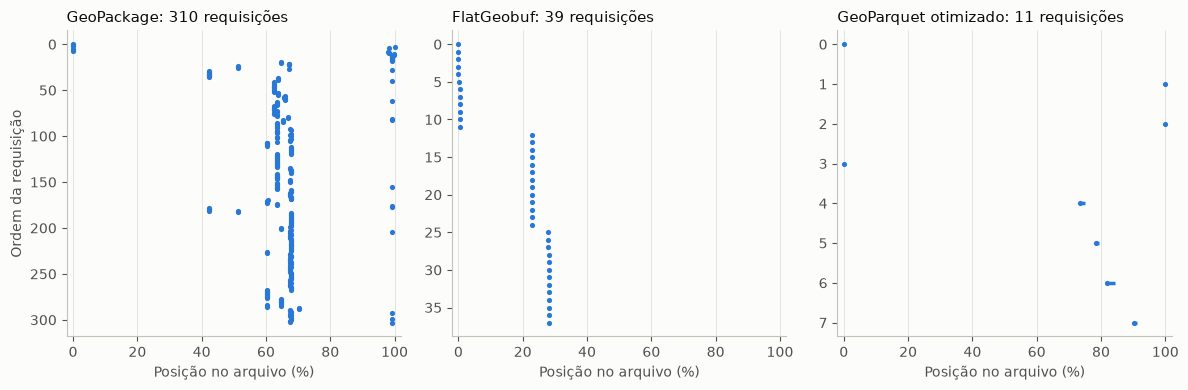

In [19]:
fig, eixos = plt.subplots(1, 3, figsize=(12, 4))
for ax, rotulo in zip(eixos, ["GeoPackage", "FlatGeobuf", "GeoParquet otimizado"]):
    nome, consulta = CONSULTAS_RECORTE[rotulo]
    pedidos, _ = pedidos_de(consulta)
    total = tamanho(ARQUIVOS[nome])
    leituras_get = [p for p in pedidos if p["metodo"] == "GET"]
    for ordem, pedido in enumerate(leituras_get):
        inicio = 100 * pedido["inicio"] / total
        fim = 100 * (pedido["inicio"] + pedido["bytes"]) / total
        ax.plot([inicio, fim], [ordem, ordem], color=AZUL, linewidth=2.5, solid_capstyle="butt")
    ax.scatter([100 * p["inicio"] / total for p in leituras_get], range(len(leituras_get)), s=14, color=AZUL, linewidths=0)
    ax.set_xlim(-2, 102)
    ax.invert_yaxis()
    ax.set_title(f"{rotulo}: {len(pedidos)} requisições")
    ax.set_xlabel("Posição no arquivo (%)")
    ax.grid(axis="x", linewidth=0.6)
    ax.set_axisbelow(True)
eixos[0].set_ylabel("Ordem da requisição")
plt.tight_layout()
plt.show()

A figura mostra por que os números diferem:

- **GeoPackage:** muitas leituras pequenas, que saltam entre a R-tree, no fim do arquivo, e as páginas de dados, a maioria entre 60 % e 70 % dele.
- **FlatGeobuf:** começa no índice, no início do arquivo, e termina em dois trechos de feições.
- **GeoParquet:** vai ao rodapé, no fim do arquivo, e depois lê só os 4 grupos que podem conter a resposta. Os pontos em 0 % são as respostas que o `fsspec` abre e abandona.

### 7.3 Consulta analítica: a área de cada UF

Agora a pergunta é outra: somar `AREA_KM2` por `CD_UF`. A resposta só precisa de 2 das 30 colunas e de nenhuma geometria, mas envolve todas as linhas. O índice espacial não ajuda em nada, e o que conta é o arranjo em colunas.

In [20]:
def colunas_gdal(nome):
    return lambda: gpd.read_file(url(nome), columns=COLUNAS, read_geometry=False)


def colunas_parquet(nome):
    return lambda: pq.read_table(url(nome), columns=COLUNAS, filesystem=FS_SEM_CACHE).to_pandas()


def colunas_geoarrow():
    with FS_SEM_CACHE.open(url("GeoArrow (IPC)"), "rb") as arquivo:
        esquema = ipc.open_file(arquivo).schema
        campos = [esquema.get_field_index(c) for c in COLUNAS]
        leitor = ipc.open_file(arquivo, options=ipc.IpcReadOptions(included_fields=campos))
        return leitor.read_all().to_pandas()


CONSULTAS_COLUNAS = {
    "Shapefile": ("Shapefile", colunas_gdal("Shapefile")),
    "GeoPackage": ("GeoPackage", colunas_gdal("GeoPackage")),
    "FlatGeobuf": ("FlatGeobuf", colunas_gdal("FlatGeobuf")),
    "GeoParquet padrão": ("GeoParquet padrão", colunas_parquet("GeoParquet padrão")),
    "GeoParquet otimizado": ("GeoParquet otimizado", colunas_parquet("GeoParquet otimizado")),
    "GeoArrow (IPC)": ("GeoArrow (IPC)", colunas_geoarrow),
}

referencia = setores.groupby("CD_UF")["AREA_KM2"].sum()
linhas = []
for rotulo, (nome, consulta) in CONSULTAS_COLUNAS.items():
    linha, resultado = medir(rotulo, consulta, tamanho(ARQUIVOS[nome]))
    soma = resultado.groupby("CD_UF")["AREA_KM2"].sum().reindex(referencia.index)
    linha["Resposta correta"] = bool(np.allclose(soma, referencia))
    linhas.append(linha)
    del resultado

remoto_colunas = pd.DataFrame(linhas).set_index("Formato")
assert remoto_colunas["Resposta correta"].all()
tabela(remoto_colunas, casas=2)

,Requisições,Transferido (MB),% do arquivo,Resposta correta
Formato,,,,
Shapefile,533,"1.083,68","46,24",True
GeoPackage,10.615,"1.465,08","98,13",True
FlatGeobuf,606,"1.406,92","98,60",True
GeoParquet padrão,7,"4,48","0,42",True
GeoParquet otimizado,54,"4,99","0,85",True
GeoArrow (IPC),50,"8,47","0,60",True


Aqui a ordem se inverte. O GeoParquet transfere cerca de 5 MB, menos de 1 % do arquivo, e o GeoArrow, 8,5 MB. GeoPackage, FlatGeobuf e Shapefile transferem mais de 200 vezes o volume do GeoParquet otimizado. O Shapefile só escapa do `.shp` porque guarda os atributos em outro arquivo, mas precisa do `.dbf` inteiro.

O GeoPackage é o caso extremo, com 10.615 requisições. A tabela também mostra um custo dos grupos pequenos: o GeoParquet otimizado faz 54 requisições, contra 7 do padrão, porque cada coluna está repartida em 47 grupos.

### 7.4 Abrir o arquivo: esquema e número de feições

Antes de qualquer consulta, um cliente precisa saber o que há no arquivo. Esta medição conta só esse primeiro passo.

In [21]:
def abrir_geoarrow():
    with FS_SEM_CACHE.open(url("GeoArrow (IPC)"), "rb") as arquivo:
        return ipc.open_file(arquivo).schema


CONSULTAS_ABRIR = {
    "Shapefile": lambda: pyogrio.read_info(f"/vsicurl/{url('Shapefile')}"),
    "GeoPackage": lambda: pyogrio.read_info(f"/vsicurl/{url('GeoPackage')}"),
    "FlatGeobuf": lambda: pyogrio.read_info(f"/vsicurl/{url('FlatGeobuf')}"),
    "GeoParquet padrão": lambda: pq.read_metadata(url("GeoParquet padrão"), filesystem=FS_SEM_CACHE),
    "GeoParquet otimizado": lambda: pq.read_metadata(url("GeoParquet otimizado"), filesystem=FS_SEM_CACHE),
    "GeoArrow (IPC)": abrir_geoarrow,
}

linhas = []
for rotulo, consulta in CONSULTAS_ABRIR.items():
    linha, _ = medir(rotulo, consulta, tamanho(ARQUIVOS[rotulo]))
    linhas.append(linha)
remoto_abrir = pd.DataFrame(linhas).set_index("Formato").drop(columns="% do arquivo")
tabela(remoto_abrir, casas=3)

,Requisições,Transferido (MB)
Formato,,
Shapefile,11,"0,049"
GeoPackage,20,"0,221"
FlatGeobuf,2,"0,016"
GeoParquet padrão,3,"0,393"
GeoParquet otimizado,4,"0,540"
GeoArrow (IPC),3,"0,007"


### 7.5 Os resultados lado a lado

O ponto azul é o que passou pela rede, e o ponto cinza é o tamanho do arquivo. Quanto maior a distância entre os dois, mais o formato evitou transferir. O eixo é logarítmico, e cada divisão vale 10 vezes a anterior.

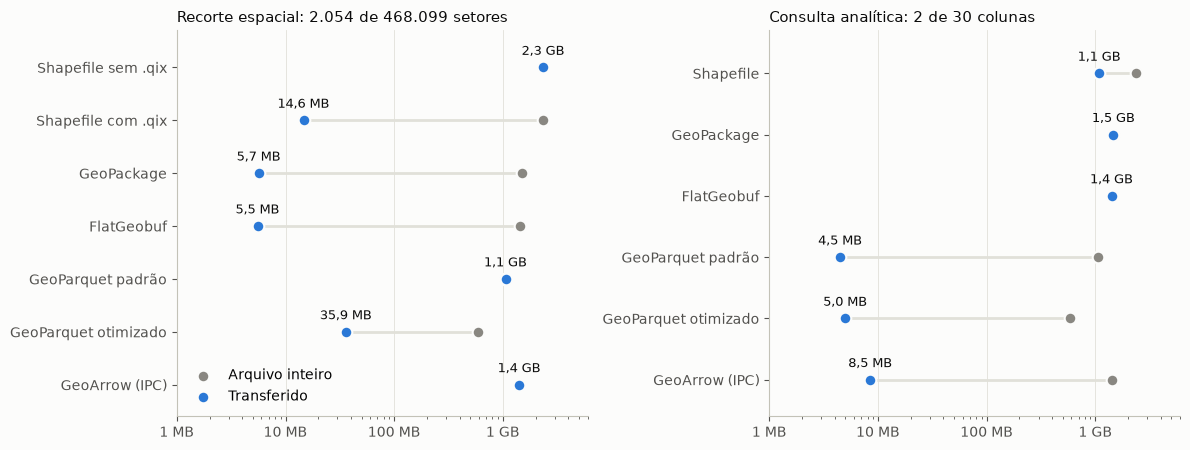

In [22]:
def grafico_transferencia(ax, resultados, titulo):
    nomes = list(resultados.index)
    y = np.arange(len(nomes))[::-1]
    transferido = resultados["Transferido (MB)"].to_numpy()
    arquivo = 100 * transferido / resultados["% do arquivo"].to_numpy()
    ax.hlines(y, transferido, arquivo, color="#e1e0d9", linewidth=2, zorder=1)
    ax.scatter(arquivo, y, s=70, color=CINZA, edgecolors="#fcfcfb", linewidths=1.5, zorder=2, label="Arquivo inteiro")
    ax.scatter(transferido, y, s=70, color=AZUL, edgecolors="#fcfcfb", linewidths=1.5, zorder=3, label="Transferido")
    for yi, valor in zip(y, transferido):
        ax.annotate(texto_bytes(valor * 1e6), (valor, yi), xytext=(0, 9), textcoords="offset points",
                    ha="center", color="#0b0b0b", fontsize=9)
    ax.set_xscale("log")
    ax.set_xlim(1, 6000)
    ax.set_ylim(-0.6, len(nomes) - 0.3)
    ax.set_yticks(y, nomes)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g} MB" if v < 1000 else f"{v / 1000:g} GB"))
    ax.set_title(titulo)
    ax.grid(axis="x", linewidth=0.6)
    ax.set_axisbelow(True)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))
grafico_transferencia(ax1, remoto_recorte, f"Recorte espacial: {br(N_RECORTE)} de {br(len(setores))} setores")
grafico_transferencia(ax2, remoto_colunas, "Consulta analítica: 2 de 30 colunas")
ax1.legend(loc="lower left", frameon=False)
plt.tight_layout()
plt.show()

### 7.6 Quanto isso custaria em uma rede real

A fórmula da seção 1 transforma as contagens em tempo. Os dois cenários são hipotéticos e podem ser alterados na célula: um acesso doméstico a um servidor distante e uma máquina na mesma região da nuvem que o arquivo. A conta assume requisições em sequência.

In [23]:
CENARIOS = {
    "Internet doméstica (s)": (0.050, 100e6),   # RTT de 50 ms, 100 Mbit/s
    "Mesma região da nuvem (s)": (0.002, 1e9),  # RTT de 2 ms, 1 Gbit/s
}


def estimar(resultados):
    estimativa = pd.DataFrame(index=resultados.index)
    for cenario, (rtt, banda) in CENARIOS.items():
        estimativa[cenario] = resultados["Requisições"] * rtt + resultados["Transferido (MB)"] * 8e6 / banda
    return estimativa


tabela(pd.concat(
    {
        "Recorte espacial": estimar(remoto_recorte),
        # A consulta por colunas foi medida com o .qix presente, e não usa o índice.
        "Consulta analítica": estimar(remoto_colunas.rename(index={"Shapefile": "Shapefile com .qix"})),
    },
    axis=1,
))

- **Em internet doméstica, a latência pesa.** No recorte, o GeoPackage leva 16 s por causa das 310 requisições, embora transfira quase o mesmo que o FlatGeobuf, que leva 2,4 s. O GeoParquet otimizado transfere 6,5 vezes mais que o FlatGeobuf e fica perto dele, com 3,4 s.
- **Na mesma região da nuvem, quase não há diferença entre os formatos com índice ou estatísticas**, todos abaixo de 1 s. O que continua caro é transferir arquivos inteiros.
- **A consulta analítica separa os grupos.** Os formatos em colunas ficam entre 0,7 e 3,2 s em internet doméstica, e os formatos em linhas, entre 113 e 648 s.

### 7.7 O cliente também conta

O `fsspec` lê, por padrão, 5 MB à frente a cada acesso, o que ajuda em leitura sequencial e atrapalha em leitura por colunas. A consulta abaixo é a da seção 7.3, com dois clientes e os mesmos dois arquivos. Todas as medições anteriores usam `cache_type="none"`, para refletir o formato e não esse ajuste.

In [24]:
fs_padrao = fsspec.filesystem("http")
linhas = []
for nome in ["GeoParquet padrão", "GeoParquet otimizado"]:
    for cliente, fs in [("fsspec padrão", fs_padrao), ("cache_type='none'", FS_SEM_CACHE)]:
        linha, _ = medir(f"{nome}, {cliente}", lambda: pq.read_table(url(nome), columns=COLUNAS, filesystem=fs), tamanho(ARQUIVOS[nome]))
        linhas.append(linha)
tabela(pd.DataFrame(linhas).set_index("Formato"), casas=2)

,Requisições,Transferido (MB),% do arquivo
Formato,,,
"GeoParquet padrão, fsspec padrão",7,"9,85","0,93"
"GeoParquet padrão, cache_type='none'",7,"4,68","0,44"
"GeoParquet otimizado, fsspec padrão",49,"258,76","43,88"
"GeoParquet otimizado, cache_type='none'",54,"5,25","0,89"


Com o cliente padrão, o GeoParquet otimizado parece muito pior que o padrão: cerca de 260 MB contra 10 MB. Sem o cache, os dois ficam em cerca de 5 MB. Uma comparação feita sem olhar o cliente concluiria, por engano, que grupos menores são ruins para consultas por coluna.

## 8. O que faz um GeoParquet ser otimizado

"Usar GeoParquet" não basta. O [guia de distribuição do projeto](https://github.com/opengeospatial/geoparquet/blob/main/format-specs/distributing-geoparquet.md) recomenda ordenar os dados no espaço, usar zstd e limitar o tamanho dos grupos. Esta seção mede cada recomendação com os mesmos dados.

### 8.1 Ordem das linhas

Os três arquivos têm as mesmas linhas, a mesma compressão e grupos de 50 mil linhas. Muda só a ordem. Cada retângulo no mapa é a extensão de um grupo, calculada a partir das estatísticas do rodapé. Um grupo só pode ser descartado se o retângulo dele não encostar na consulta.

In [25]:
VARIANTE = dict(OTIMIZADO, row_group_size=50_000)
setores_aleatorios = setores.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

ORDENS = {
    "Aleatória": gravar("Ordem aleatória", OUTPUT_DIR / "ordem_aleatoria.parquet", lambda p: setores_aleatorios.to_parquet(p, **VARIANTE)),
    "Do IBGE": gravar("Ordem do IBGE", OUTPUT_DIR / "ordem_ibge.parquet", lambda p: setores.to_parquet(p, **VARIANTE)),
    "Hilbert": gravar("Ordem de Hilbert", OUTPUT_DIR / "ordem_hilbert.parquet", lambda p: setores_hilbert.to_parquet(p, **VARIANTE)),
}
del setores_aleatorios


def caixas_dos_grupos(caminho):
    meta = pq.read_metadata(caminho)
    nomes = {meta.row_group(0).column(j).path_in_schema: j for j in range(meta.row_group(0).num_columns)}
    caixas = []
    for i in range(meta.num_row_groups):
        grupo = meta.row_group(i)
        caixas.append((
            grupo.column(nomes["bbox.xmin"]).statistics.min, grupo.column(nomes["bbox.ymin"]).statistics.min,
            grupo.column(nomes["bbox.xmax"]).statistics.max, grupo.column(nomes["bbox.ymax"]).statistics.max,
        ))
    return caixas


def cruza(caixa):
    return caixa[0] <= BBOX[2] and caixa[2] >= BBOX[0] and caixa[1] <= BBOX[3] and caixa[3] >= BBOX[1]


def medir_parquet(rotulo, caminho, **opcoes):
    linha, resultado = medir(
        rotulo, lambda: gpd.read_parquet(f"{BASE}/{caminho.name}", bbox=BBOX, storage_options=SEM_CACHE, **opcoes), caminho.stat().st_size,
    )
    assert len(filtrar(resultado)) == N_RECORTE
    meta = pq.read_metadata(caminho)
    colunas_fisicas = {meta.schema.column(i).path for i in range(meta.num_columns)}
    caixas = caixas_dos_grupos(caminho) if "bbox.xmin" in colunas_fisicas else []
    return {
        "Formato": rotulo,
        "Arquivo (MB)": caminho.stat().st_size / 1e6,
        "Grupos": meta.num_row_groups,
        "Grupos lidos": sum(cruza(c) for c in caixas) if caixas else np.nan,
        "Rodapé (KB)": meta.serialized_size / 1e3,
        "Requisições": linha["Requisições"],
        "Transferido (MB)": linha["Transferido (MB)"],
    }


por_ordem = pd.DataFrame([medir_parquet(rotulo, caminho) for rotulo, caminho in ORDENS.items()]).set_index("Formato")
por_ordem.index.name = "Ordem"
tabela(por_ordem)

,Arquivo (MB),Grupos,Grupos lidos,Rodapé (KB),Requisições,Transferido (MB)
Ordem,,,,,,
Aleatória,"918,8",10,10,"54,2",27,"919,2"
Do IBGE,"633,3",10,6,"56,0",18,"383,9"
Hilbert,"589,0",10,4,"53,9",13,"166,8"


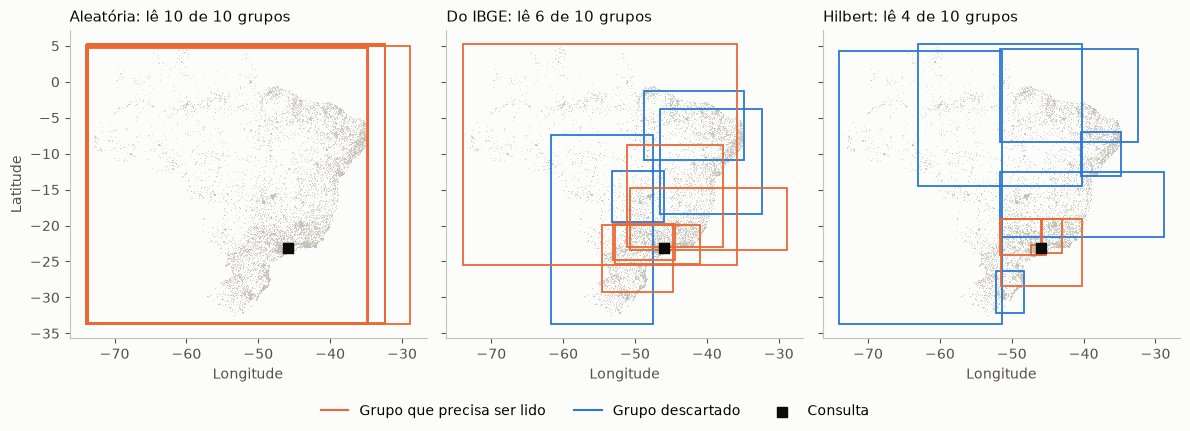

In [26]:
fig, eixos = plt.subplots(1, 3, figsize=(12, 4.6), sharex=True, sharey=True)
for ax, (rotulo, caminho) in zip(eixos, ORDENS.items()):
    ax.scatter(amostra.x, amostra.y, s=0.2, color="#c3c2b7", linewidths=0)
    caixas = caixas_dos_grupos(caminho)
    for caixa in caixas:
        lido = cruza(caixa)
        ax.add_patch(Rectangle(caixa[:2], caixa[2] - caixa[0], caixa[3] - caixa[1], fill=False,
                               edgecolor=LARANJA if lido else AZUL, linewidth=1.3, zorder=3 if lido else 2))
    ax.scatter((BBOX[0] + BBOX[2]) / 2, (BBOX[1] + BBOX[3]) / 2, s=45, marker="s", color="#0b0b0b", zorder=4)
    ax.set_title(f"{rotulo}: lê {sum(cruza(c) for c in caixas)} de {len(caixas)} grupos")
    ax.set_aspect("equal")
    ax.set_xlabel("Longitude")
eixos[0].set_ylabel("Latitude")
eixos[0].plot([], [], color=LARANJA, label="Grupo que precisa ser lido")
eixos[0].plot([], [], color=AZUL, label="Grupo descartado")
eixos[0].scatter([], [], s=45, marker="s", color="#0b0b0b", label="Consulta")
fig.legend(*eixos[0].get_legend_handles_labels(), loc="lower center", ncol=3, frameon=False)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

- **Aleatória:** cada grupo cobre o Brasil inteiro, nada pode ser descartado, e o arquivo inteiro viaja. É o que pode acontecer depois de uma junção ou de uma amostragem sem reordenar.
- **Do IBGE:** o arquivo segue o código do setor, em duas sequências crescentes, o que agrupa estados e municípios. Isso ajuda, mas as caixas ainda se sobrepõem, e 6 de 10 grupos são lidos.
- **Hilbert:** as caixas se sobrepõem bem menos. O retângulo cai na junção de 4 grupos, e a transferência é menos da metade da ordem do IBGE.

A ordem também melhora a compressão: o mesmo conteúdo ocupa 919 MB em ordem aleatória, 633 MB na ordem do IBGE e 589 MB em Hilbert, porque valores parecidos ficam juntos. Da redução em relação aos 1.056 MB do GeoParquet padrão, a maior parte vem de trocar snappy por zstd, e o restante, da ordenação.

### 8.2 Tamanho dos grupos

Com a ordem de Hilbert fixa, o tamanho do grupo define o equilíbrio: grupos menores permitem descartar mais dados, mas aumentam o rodapé, que todo cliente precisa baixar para abrir o arquivo. O guia sugere, como ponto de partida, de 50 mil a 150 ou 200 mil linhas por grupo. O resumo e o corpo do texto trazem limites diferentes.

In [27]:
GRUPOS = {
    2_000: gravar("Grupos de 2 mil", OUTPUT_DIR / "grupos_2000.parquet", lambda p: setores_hilbert.to_parquet(p, **dict(OTIMIZADO, row_group_size=2_000))),
    10_000: ARQUIVOS["GeoParquet otimizado"],
    50_000: ORDENS["Hilbert"],
    100_000: gravar("Grupos de 100 mil", OUTPUT_DIR / "grupos_100000.parquet", lambda p: setores_hilbert.to_parquet(p, **dict(OTIMIZADO, row_group_size=100_000))),
}
por_grupo = pd.DataFrame([medir_parquet(br(n), caminho) for n, caminho in GRUPOS.items()]).set_index("Formato")
por_grupo.index.name = "Linhas por grupo"
tabela(por_grupo)

,Arquivo (MB),Grupos,Grupos lidos,Rodapé (KB),Requisições,Transferido (MB)
Linhas por grupo,,,,,,
2.000,"591,7",235,5,"990,4",11,"12,9"
10.000,"589,7",47,4,"212,7",11,"35,9"
50.000,"589,0",10,4,"53,9",13,"166,9"
100.000,"588,0",5,4,"35,5",16,"499,5"


O tamanho do arquivo quase não muda, mas o recorte vai de 500 MB, com grupos de 100 mil linhas, a 13 MB, com grupos de 2 mil. O rodapé faz o caminho inverso, de 36 KB a 990 KB, e a seção 7.3 mostrou que grupos menores também multiplicam as requisições em consultas por coluna.

O arquivo chamado de otimizado neste notebook usa 10 mil linhas, abaixo da faixa sugerida pelo guia. A escolha privilegia recortes pequenos em um arquivo de 468 mil linhas. Para consultas analíticas ou arquivos muito maiores, a faixa do guia é o ponto de partida mais seguro, como mostra o exemplo de 17,6 GB da seção 9.

### 8.3 Compressão e versões do formato

A última tabela compara outras decisões de gravação. Todas usam a ordem de Hilbert e grupos de 10 mil linhas, exceto a comparação de compressão, que parte do arquivo de 50 mil linhas da seção 8.1 para testar o nível 15 recomendado pelo guia.

In [28]:
Z15 = gravar("zstd 15", OUTPUT_DIR / "zstd15.parquet", lambda p: setores_hilbert.to_parquet(p, **dict(VARIANTE, compression_level=15)))
NATIVO = gravar("GeoParquet 1.1 nativo", OUTPUT_DIR / "geoarrow_nativo.parquet", lambda p: setores_hilbert.to_parquet(p, **OTIMIZADO, geometry_encoding="geoarrow"))
V2 = gravar("GeoParquet 2.0", OUTPUT_DIR / "geoparquet_2.parquet", lambda p: setores_hilbert.to_parquet(
    p, compression="zstd", compression_level=9, row_group_size=10_000, schema_version="2.0.0"))

meta_v2 = pq.read_metadata(V2)
indice_geo = pq.read_schema(V2).get_field_index("geometry")
print("Tipo da geometria no GeoParquet 2.0:", str(meta_v2.schema.column(indice_geo).logical_type).split("(")[0])
print("Coluna bbox no 2.0:", "bbox" in pq.read_schema(V2).names)

decisoes = pd.DataFrame([
    medir_parquet("zstd 9, grupos de 50 mil", ORDENS["Hilbert"]),
    medir_parquet("zstd 15, grupos de 50 mil", Z15),
    medir_parquet("WKB, GeoParquet 1.1, grupos de 10 mil", ARQUIVOS["GeoParquet otimizado"]),
    medir_parquet("O mesmo arquivo, lendo só código e geometria", ARQUIVOS["GeoParquet otimizado"], columns=["CD_SETOR", "geometry"]),
    medir_parquet("GeoArrow nativo, GeoParquet 1.1, grupos de 10 mil", NATIVO),
    medir_parquet("Tipos nativos, GeoParquet 2.0 RC, grupos de 10 mil", V2),
]).set_index("Formato").drop(columns="Grupos lidos")
decisoes.index.name = "Decisão"
decisoes["Gravação (s)"] = [
    tempos["Ordem de Hilbert"], tempos["zstd 15"], tempos["GeoParquet otimizado"], np.nan,
    tempos["GeoParquet 1.1 nativo"], tempos["GeoParquet 2.0"],
]
tabela(decisoes)

Tipo da geometria no GeoParquet 2.0: Geometry
Coluna bbox no 2.0: False


,Arquivo (MB),Grupos,Rodapé (KB),Requisições,Transferido (MB),Gravação (s)
Decisão,,,,,,
"zstd 9, grupos de 50 mil","589,0",10,"53,9",13,"167,0","29,4"
"zstd 15, grupos de 50 mil","578,3",10,"53,9",13,"164,9","84,2"
"WKB, GeoParquet 1.1, grupos de 10 mil","589,7",47,"212,7",11,"35,9","29,5"
"O mesmo arquivo, lendo só código e geometria","589,7",47,"212,7",15,"35,4",–
"GeoArrow nativo, GeoParquet 1.1, grupos de 10 mil","709,9",47,"203,7",11,"42,1","31,3"
"Tipos nativos, GeoParquet 2.0 RC, grupos de 10 mil","574,2",47,"169,2",11,"34,4","25,4"


- **Nível de compressão:** o zstd 15 reduz o arquivo em 1,8 % e leva quase 3 vezes mais para gravar que o zstd 9. O guia recomenda 15 ou mais, o que faz sentido para um arquivo gravado uma vez e lido muitas.
- **Menos colunas no recorte:** pedir só o código e a geometria quase não muda a transferência, porque a geometria é 96 % do arquivo.
- **GeoArrow nativo dentro do Parquet:** neste conjunto, o arquivo fica 20 % maior e não há ganho na transferência. O GeoParquet 2.0 remove essa codificação.
- **GeoParquet 2.0 RC:** a geometria usa o tipo nativo do Parquet, a coluna `bbox` deixa de ser necessária, e o arquivo e o rodapé ficam menores. O GeoPandas filtrou o recorte pelas estatísticas nativas, com o mesmo número de requisições. Ainda é *release candidate*, e o próprio guia mantém a coluna `bbox` como opção para leitores que não usam essas estatísticas.

## 9. Na rede de verdade

Até aqui, o servidor era local, para que a contagem fosse exata. Agora, três consultas a arquivos públicos, com o tempo real da rede. Os bytes não são contados, porque essas leituras não passam pelo servidor do notebook.

Dois cuidados, ambos encontrados nos testes de 30/10/2026:

- O GeoPackage do IBGE é lido por `http://` de propósito. Neste Windows, com o GDAL do pacote `pyogrio`, processos que leram por `https://` ficaram presos ao encerrar, e os que leram por `http://` terminaram normalmente.
- O código não chama `pyogrio.read_info` nesse arquivo. A chamada não terminou em mais de 10 minutos. O arquivo do IBGE não tem a tabela `gpkg_ogr_contents`, que guarda a contagem de feições, então a causa provável é uma contagem varrendo o arquivo pela rede.

As falhas de rede são apenas relatadas, para não interromper o notebook.

In [29]:
def na_rede(rotulo, funcao):
    inicio = perf_counter()
    try:
        return {"Consulta": rotulo, "Resultado": funcao(), "Tempo (s)": perf_counter() - inicio}
    except Exception as erro:
        return {"Consulta": rotulo, "Resultado": f"falhou: {type(erro).__name__}", "Tempo (s)": np.nan}


URL_BRA = "https://data.source.coop/vida/google-microsoft-open-buildings/geoparquet/by_country/country_iso=BRA/BRA.parquet"
URL_GPKG_IBGE = f"http://{IBGE_SETORES}/gpkg/BR/BR_setores_CD2022.gpkg"
resposta_ibge = {}


def rodape_bra():
    resposta = requests.get(URL_BRA, headers={"Range": "bytes=-8"}, timeout=60)
    resposta.raise_for_status()
    total = int(resposta.headers["Content-Range"].rsplit("/", 1)[1])
    rodape = struct.unpack("<I", resposta.content[:4])[0]
    return f"arquivo de {texto_bytes(total)}, rodapé de {texto_bytes(rodape)}, assinatura {resposta.content[4:].decode()}"


def recorte_ibge():
    total = int(requests.head(URL_GPKG_IBGE, timeout=30).headers["Content-Length"])
    resposta_ibge["gdf"] = gpd.read_file(URL_GPKG_IBGE, bbox=BBOX)
    return f"{br(len(resposta_ibge['gdf']))} linhas de um arquivo de {texto_bytes(total)}"


def recorte_overture():
    versao = requests.get("https://stac.overturemaps.org/catalog.json", timeout=30).json()["latest"]
    s3 = pafs.S3FileSystem(anonymous=True, region="us-west-2", connect_timeout=20, request_timeout=60)
    pasta = f"overturemaps-us-west-2/release/{versao}/theme=places/type=place/"
    partes = [p for p in s3.get_file_info(pafs.FileSelector(pasta)) if p.size]
    with s3.open_input_file(partes[0].path) as arquivo:
        meta_parte = pq.read_metadata(arquivo)
    lugares = gpd.read_parquet(pasta, bbox=BBOX, columns=["id", "names", "geometry"], filesystem=s3)
    return (
        f"{br(len(lugares))} lugares de {len(partes)} arquivos com {texto_bytes(sum(p.size for p in partes))}, versão {versao}. "
        f"O primeiro arquivo tem {meta_parte.num_row_groups} grupos e rodapé de {texto_bytes(meta_parte.serialized_size)}"
    )


rede = pd.DataFrame([
    na_rede("Rodapé de um GeoParquet: 8 bytes finais", rodape_bra),
    na_rede("GeoPackage do IBGE: recorte com o GDAL", recorte_ibge),
    na_rede("GeoParquet do Overture no S3: recorte com o pyarrow", recorte_overture),
]).set_index("Consulta")
tabela(rede)

,Resultado,Tempo (s)
Consulta,,
Rodapé de um GeoParquet: 8 bytes finais,"arquivo de 17,6 GB, rodapé de 50,0 MB, assinatura PAR1","1,7"
GeoPackage do IBGE: recorte com o GDAL,"2.061 linhas de um arquivo de 1,5 GB","10,2"
GeoParquet do Overture no S3: recorte com o pyarrow,"37.531 lugares de 16 arquivos com 11,9 GB, versão 2026-10-21.0. O primeiro arquivo tem 256 grupos e rodapé de 1,6 MB","16,8"


In [30]:
if "gdf" in resposta_ibge:
    do_ibge = resposta_ibge["gdf"]
    codigos_ibge, codigos_recorte = set(do_ibge["CD_SETOR"]), set(recorte["CD_SETOR"])
    print(f"Linhas no GeoPackage do IBGE: {br(len(do_ibge))}, com {br(len(codigos_ibge))} códigos de setor. Tipos: {do_ibge.geom_type.value_counts().to_dict()}")
    print(f"Códigos em comum com o Shapefile do IBGE: {br(len(codigos_ibge & codigos_recorte))} de {br(len(codigos_recorte))}")
    multipartes = recorte[recorte["CD_SETOR"].isin(do_ibge.loc[do_ibge["CD_SETOR"].duplicated(), "CD_SETOR"])]
    print("Setores com mais de uma linha, tipo no Shapefile:", multipartes.geom_type.value_counts().to_dict())

Linhas no GeoPackage do IBGE: 2.061, com 2.054 códigos de setor. Tipos: {'Polygon': 2061}
Códigos em comum com o Shapefile do IBGE: 2.054 de 2.054
Setores com mais de uma linha, tipo no Shapefile: {'MultiPolygon': 2}


- **Rodapé.** Cerca de dois segundos e 8 bytes bastam para saber que esse arquivo de 17,6 GB tem um rodapé de 50 MB. Lido uma vez à parte, em 30/10/2026, ele mostra 141 milhões de edifícios em 28.210 grupos de 5 mil linhas. Os dados têm coluna `bbox` e o primeiro grupo cobre só cerca de 1,4° por 1,6°, sinal de ordenação espacial, mas todo cliente precisa baixar 50 MB antes da primeira consulta. É o equilíbrio da seção 8.2 em escala real.
- **GeoPackage do IBGE.** O recorte levou de 8 a 35 s nas execuções de 30/10 e 01/11/2026, a mesma ordem de grandeza dos 16 s estimados na seção 7.6. Baixar o arquivo inteiro levaria cerca de 2 minutos a 100 Mbit/s. Funciona, mas o ganho é bem menor do que o tamanho do recorte sugere.
- **Overture no S3.** A consulta levou de 15 a 40 s nas mesmas datas, para encontrar cerca de 37 mil lugares em 11,9 GB. O conjunto usa GeoParquet 1.1 com coluna `bbox` e divide os dados em 16 arquivos.

O GeoPackage do IBGE devolve mais linhas que o Shapefile porque guarda cada parte de um setor multipartido em uma linha própria, em vez de um `MultiPolygon`. Os códigos de setor são os mesmos. Dois arquivos no mesmo formato podem ter estrutura e custo diferentes: o do IBGE também não tem a tabela de contagem citada acima.

## 10. Síntese

A tabela reúne as medições deste notebook. As colunas de rede são contagens do servidor, válidas para esta consulta e estes clientes, e no recorte a linha do Shapefile usa o `.qix`.

As contagens se repetem. Em um teste à parte, em 01/11/2026, cinco repetições de cada consulta não mudaram o número de requisições. Os bytes só variaram no GeoParquet, em menos de 0,3 MB, por causa das respostas que o `fsspec` abandona.

In [31]:
sintese = pd.DataFrame({
    "Arquivo (MB)": gravacao["Tamanho (MB)"],
    "Leitura local (s)": leitura_local["Leitura (s)"],
    "Recorte: requisições": remoto_recorte["Requisições"],
    "Recorte: MB": remoto_recorte["Transferido (MB)"],
    "Colunas: requisições": remoto_colunas["Requisições"],
    "Colunas: MB": remoto_colunas["Transferido (MB)"],
}).reindex(["Shapefile", "GeoPackage", "FlatGeobuf", "GeoParquet padrão", "GeoParquet otimizado", "GeoArrow (IPC)"])
# Linha do Shapefile no recorte: valor com o índice .qix. Sem ele, o arquivo inteiro é transferido.
sintese.loc["Shapefile", "Recorte: requisições"] = remoto_recorte.loc["Shapefile com .qix", "Requisições"]
sintese.loc["Shapefile", "Recorte: MB"] = remoto_recorte.loc["Shapefile com .qix", "Transferido (MB)"]
tabela(sintese.astype({"Recorte: requisições": int, "Colunas: requisições": int}))

,Arquivo (MB),Leitura local (s),Recorte: requisições,Recorte: MB,Colunas: requisições,Colunas: MB
Shapefile,"2.343,5","11,1",151,"14,6",533,"1.083,7"
GeoPackage,"1.493,0","11,1",310,"5,7",10.615,"1.465,1"
FlatGeobuf,"1.426,9","10,8",39,"5,5",606,"1.406,9"
GeoParquet padrão,"1.055,7","4,8",8,"1.056,3",7,"4,5"
GeoParquet otimizado,"589,7","3,9",11,"35,9",54,"5,0"
GeoArrow (IPC),"1.410,6","2,1",18,"1.410,6",50,"8,5"


### Cada formato é *cloud-optimized*?

| Formato | Metadados | Descarte sem ler | Organização física | Veredito |
|---|---|---|---|---|
| Shapefile | Em vários arquivos | Só com `.qix` | Ordem de gravação | Não. Com `.qix`, funciona, mas exige muitas requisições |
| GeoPackage | Nas páginas iniciais | R-tree | Não é garantida | Não foi feito para isso. Lê pouco, em muitas requisições |
| FlatGeobuf | No início | R-tree | Hilbert, automática | Sim, para recortes. Não para consultas por coluna |
| GeoParquet | No rodapé | Estatísticas por grupo | Depende de quem grava | Sim, para análise, e para recortes se bem gravado |
| GeoArrow | No rodapé do IPC | Não | Depende de quem grava | Não é um formato de distribuição. É a camada de memória e de troca |

### Quando usar cada um

| Formato | Use quando | Evite quando |
|---|---|---|
| Shapefile | Um sistema só aceita esse formato | Houver acesso remoto, nomes longos, data com hora ou mais de 2 GB |
| GeoPackage | Trabalho local em SIG, edição, várias camadas, SQL | Muitos clientes consultarem o arquivo remotamente |
| FlatGeobuf | Recortes remotos de dados estáticos, sem servidor de mapas | Consultas por coluna ou dados que mudam com frequência |
| GeoParquet | Análise de grandes volumes, leitura por colunas, arquivos particionados | For gravado sem ordem espacial e sem estatísticas úteis |
| GeoArrow | Troca entre bibliotecas e processamento na memória | Precisar de índice ou de um arquivo compacto para distribuir |

A tabela da aula 03 continua válida, com um acréscimo: o formato define o que é possível, mas a forma de gravar e o cliente definem o custo real.

### Limitações

- O teste usa um único conjunto de dados, de polígonos detalhados, com média de 163 vértices por setor, e um único recorte. Com pontos, a geometria deve pesar bem menos.
- As contagens valem para os clientes usados: GDAL `/vsicurl/`, que lê em blocos de 16 KB por padrão, e `pyarrow` com `fsspec`. Outros clientes dariam outros números.
- A estimativa de tempo supõe requisições em sequência, e clientes com leitura paralela levariam menos.
- A pasta `output/` ocupa cerca de 13 GB, porque guarda todas as variantes testadas.

### Referências

**Material do curso**

- Aula 02, *Spatial representation and CRS*, e aula 03, *Geospatial file formats and packages*, com o notebook correspondente

**Especificações e documentação** (consultadas em 30/10/2026)

- [GeoParquet: versões](https://github.com/opengeospatial/geoparquet/releases) e [guia de distribuição](https://github.com/opengeospatial/geoparquet/blob/main/format-specs/distributing-geoparquet.md)
- [FlatGeobuf](https://flatgeobuf.org/)
- [GeoArrow: layout de memória](https://github.com/geoarrow/geoarrow/blob/main/format.md)
- [GeoPackage](https://www.geopackage.org/) e [especificação](https://www.geopackage.org/spec/)
- [GDAL: driver de Shapefile](https://gdal.org/en/stable/drivers/vector/shapefile.html) e [`/vsicurl/`](https://gdal.org/en/stable/user/virtual_file_systems.html#vsicurl-http-https-ftp-files-random-access)

**Dados**

- [IBGE: malha de setores censitários de 2022](https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/malhas_de_setores_censitarios__divisoes_intramunicipais/censo_2022/setores/)
- [Google-Microsoft Open Buildings no Source Coop](https://source.coop/vida/google-microsoft-open-buildings)
- [Overture Maps](https://docs.overturemaps.org/)

In [32]:
servidor.terminate()
servidor.wait(timeout=10)
print("Servidor encerrado.")

Servidor encerrado.
